In [1]:
# This loads the packages, finds the Level-1C image and loads the saved no-leak model.
# Level-1C is required because the model was trained on top-of-atmosphere reflectance and uses B10.
# Full paths are used so this notebook works from any folder.

import json
import xml.etree.ElementTree as ET
from pathlib import Path

import h5py
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
from catboost import CatBoostClassifier
from rasterio.enums import Resampling
from rasterio.transform import Affine
from scipy.ndimage import binary_erosion


In [2]:
# conda install -n alluvialfans -c conda-forge libgdal-jp2openjpeg -y

In [3]:

REPO = Path("/Users/varyabazilova/Desktop/looking_for_jobs/planet_datascience/task/repo")
DATA_DIR, MODEL_DIR, FIG_DIR = REPO / "data", REPO / "model", REPO / "figures"
FIG_DIR.mkdir(exist_ok=True)
# /Users/varyabazilova/Desktop/looking_for_jobs/planet_datascience/task/repo/data/S2B_MSIL1C_20261105T045959_N0513_R119_T45RTM_20261105T082324.SAFE
found = sorted(DATA_DIR.glob("S2B_MSIL1C_20261105T045959*.SAFE"))
assert len(found) == 1, f"Expected one L1C folder in repo/data, found: {[p.name for p in found]}"
SAFE_PATH = found[0]
print("Using:", SAFE_PATH.name)

model = CatBoostClassifier()
model.load_model(str(MODEL_DIR / "final_scene_4class.cbm"))
with open(MODEL_DIR / "final_scene_4class.json") as f:
    info = json.load(f)

TARGET_NAMES = info["classes"]
bands = info["band_order"]
assert list(model.classes_) == [0, 1, 2, 3]
print(info)

Using: S2B_MSIL1C_20261105T045959_N0513_R119_T45RTM_20261105T082324.SAFE
{'classes': ['Rest', 'Cloud', 'Snow', 'Water'], 'band_order': ['B1', 'B2', 'B3', 'B4', 'B5', 'B6', 'B7', 'B8', 'B8a', 'B9', 'B10', 'B11', 'B12'], 'cloud_threshold': 0.5, 'input': 'top-of-atmosphere reflectance (Sentinel-2 Level-1C)'}


In [4]:
# Digital numbers are converted to reflectance using the offset and scale in the image's own metadata.
# All 13 bands are averaged to the 60 m grid and stacked in the model's band order, with B8A ninth.
# The value ranges are then compared with the training data, to catch scaling errors.

BAND_FILES = ["B01", "B02", "B03", "B04", "B05", "B06", "B07",
              "B08", "B8A", "B09", "B10", "B11", "B12"]
assert [b.upper() for b in bands] == ["B1", "B2", "B3", "B4", "B5", "B6", "B7",
                                      "B8", "B8A", "B9", "B10", "B11", "B12"]

root = ET.parse(SAFE_PATH / "MTD_MSIL1C.xml").getroot()
def meta(tag):
    return next((e.text for e in root.iter() if e.tag.split("}")[-1] == tag), None)

quantification = float(meta("QUANTIFICATION_VALUE"))
offsets = {int(e.attrib["band_id"]): float(e.text)
           for e in root.iter() if e.tag.split("}")[-1] == "RADIO_ADD_OFFSET"}
print("Product:", meta("PRODUCT_URI"))
print("Baseline:", meta("PROCESSING_BASELINE"), "| Scale:", quantification,
      "| Offsets:", sorted(set(offsets.values())) or "none")

granules = [p for p in (SAFE_PATH / "GRANULE").iterdir() if p.is_dir()]
assert len(granules) == 1, f"Expected one granule, found {len(granules)}"

def band_path(name):
    matches = list((granules[0] / "IMG_DATA").glob(f"*_{name}.jp2"))
    assert len(matches) == 1, f"Expected one file for {name}, found {len(matches)}"
    return matches[0]

with rasterio.open(band_path("B01")) as src:
    height, width = src.height, src.width
    transform, crs = src.transform, src.crs
    assert abs(transform.a) == 60, f"Expected a 60 m grid, got {transform.a}"

image = np.empty((height, width, 13), dtype=np.float32)
valid = np.ones((height, width), dtype=bool)
for i, name in enumerate(BAND_FILES):
    with rasterio.open(band_path(name)) as src:
        dn = src.read(1, out_shape=(height, width), resampling=Resampling.average).astype(np.float32)
    valid &= dn > 0                        # 0 means no data
    image[:, :, i] = (dn + offsets.get(i, 0.0)) / quantification
    print(f"{name} done")

valid = binary_erosion(valid, iterations=1)   # removes mixed pixels at the image edge
image = np.clip(image, 0, None)               # the training spectra contain no negative values
image[~valid] = np.nan

with h5py.File(DATA_DIR / "20170710_s2_manual_classification_data.h5") as f:
    X_train = f["spectra"][()].astype(np.float64)

check = pd.DataFrame({
    "image_p1": np.nanpercentile(image, 1, axis=(0, 1)),
    "image_median": np.nanmedian(image, axis=(0, 1)),
    "image_p99": np.nanpercentile(image, 99, axis=(0, 1)),
    "training_p1": np.percentile(X_train, 1, axis=0),
    "training_median": np.median(X_train, axis=0),
    "training_p99": np.percentile(X_train, 99, axis=0),
}, index=bands)
print(f"\nShape: {image.shape} | Valid pixels: {valid.mean():.1%} | Pixels to predict: {valid.sum():,}")
print(check.round(3).to_string())

Product: S2B_MSIL1C_20261105T045959_N0513_R119_T45RTM_20261105T082324.SAFE
Baseline: 05.13 | Scale: 10000.0 | Offsets: [-1000.0]
B01 done
B02 done
B03 done
B04 done
B05 done
B06 done
B07 done
B08 done
B8A done
B09 done
B10 done
B11 done
B12 done

Shape: (1830, 1830, 13) | Valid pixels: 99.8% | Pixels to predict: 3,341,584
     image_p1  image_median  image_p99  training_p1  training_median  training_p99
B1      0.086         0.162      1.165        0.100            0.175         1.309
B2      0.060         0.136      1.209        0.073            0.150         1.389
B3      0.040         0.124      1.185        0.050            0.148         1.376
B4      0.024         0.125      1.228        0.028            0.164         1.525
B5      0.027         0.144      1.226        0.024            0.181         1.568
B6      0.036         0.230      1.207        0.021            0.247         1.573
B7      0.039         0.272      1.164        0.019            0.275         1.556
B8      0.03

In [5]:
# The model gives each valid pixel a probability for Rest, Cloud, Snow and Water.
# These values sum to 1 for each pixel, and no threshold is applied here.
# They are saved as a GeoTIFF, which can be opened on a map in GIS software.

probabilities = np.full((height, width, len(TARGET_NAMES)), np.nan, dtype=np.float32)
probabilities[valid] = model.predict_proba(image[valid])
assert np.allclose(np.nansum(probabilities, axis=2)[valid], 1, atol=1e-4)

with rasterio.open(DATA_DIR / "real_scene_probabilities.tif", "w", driver="GTiff", compress="deflate",
                   height=height, width=width, count=len(TARGET_NAMES), dtype="float32",
                   nodata=np.nan, crs=crs, transform=transform) as dst:
    for i, name in enumerate(TARGET_NAMES):
        dst.write(probabilities[:, :, i], i + 1)
        dst.set_band_description(i + 1, f"P({name})")

print(pd.DataFrame(probabilities[valid], columns=TARGET_NAMES).describe().round(3).to_string())

              Rest        Cloud         Snow        Water
count  3341584.000  3341584.000  3341584.000  3341584.000
mean         0.664        0.088        0.241        0.007
std          0.442        0.248        0.407        0.046
min          0.000        0.000        0.000        0.000
25%          0.042        0.000        0.000        0.000
50%          0.995        0.000        0.000        0.000
75%          0.999        0.013        0.406        0.001
max          1.000        1.000        1.000        1.000


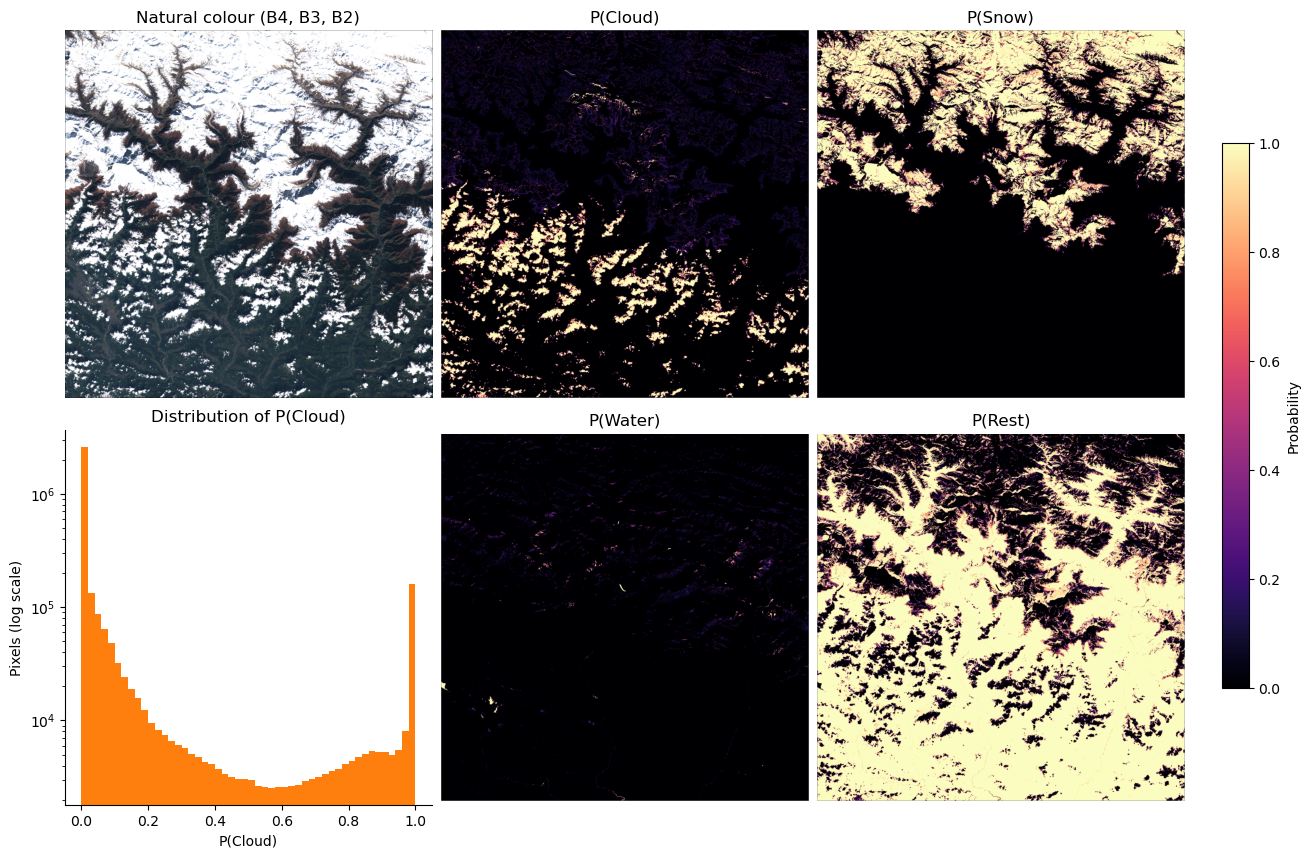

P(Cloud) >= 0.5: 7.6% of pixels
P(Cloud) between 0.2 and 0.8: 3.7% of pixels


In [6]:
# Figure 3 shows the image beside the model's probability map for each class.
# The histogram shows how confident the model is about Cloud across the image.
# Values are model probabilities, and were not calibrated for this image.

index = {b: i for i, b in enumerate(BAND_FILES)}
rgb = np.clip(np.nan_to_num(image[:, :, [index["B04"], index["B03"], index["B02"]]]) / 0.4, 0, 1)
map_panels = {"B": "Cloud", "C": "Snow", "E": "Water", "F": "Rest"}

fig, axd = plt.subplot_mosaic("ABC;DEF", figsize=(13, 8.5), layout="constrained")
axd["A"].imshow(rgb)
axd["A"].set_title("Natural colour (B4, B3, B2)")

for key, name in map_panels.items():
    im = axd[key].imshow(probabilities[:, :, TARGET_NAMES.index(name)], vmin=0, vmax=1, cmap="magma")
    axd[key].set_title(f"P({name})")

for key in ["A", "B", "C", "E", "F"]:
    axd[key].axis("off")

p_cloud = probabilities[:, :, TARGET_NAMES.index("Cloud")][valid]
axd["D"].hist(p_cloud, bins=50, range=(0, 1), color="tab:orange")
axd["D"].set_yscale("log")
axd["D"].set(xlabel="P(Cloud)", ylabel="Pixels (log scale)", title="Distribution of P(Cloud)")
axd["D"].spines[["top", "right"]].set_visible(False)

fig.colorbar(im, ax=[axd["B"], axd["C"], axd["E"], axd["F"]], label="Probability", shrink=0.7)
fig.savefig(FIG_DIR / "fig3_real_image.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig3_real_image.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"P(Cloud) >= 0.5: {(p_cloud >= 0.5).mean():.1%} of pixels")
print(f"P(Cloud) between 0.2 and 0.8: {((p_cloud > 0.2) & (p_cloud < 0.8)).mean():.1%} of pixels")

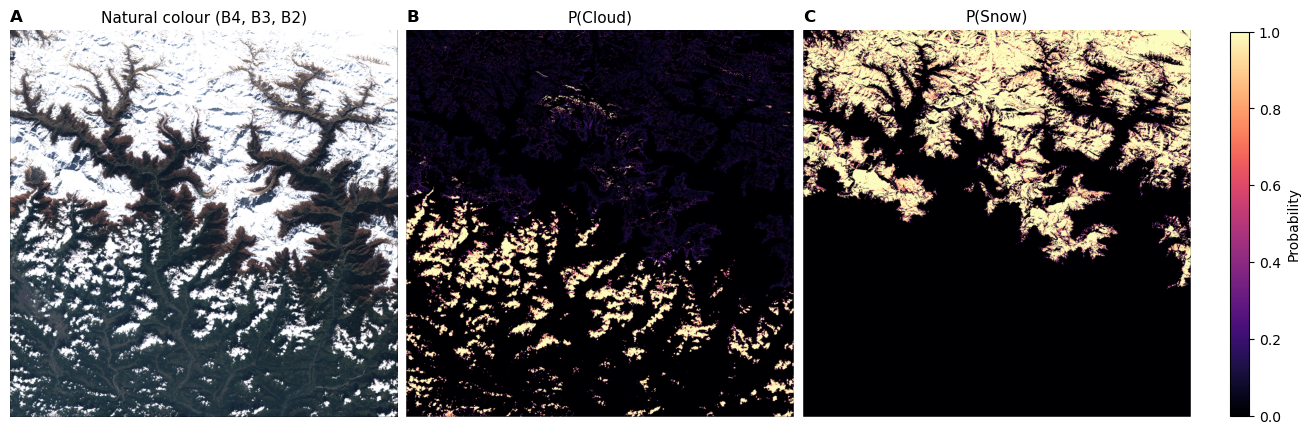

P(Cloud) >= 0.5: 7.6% of pixels
P(Cloud) between 0.2 and 0.8: 3.7% of pixels


In [9]:
# This figure shows the image beside the model's Cloud and Snow probabilities.
# Each map uses the same colour scale, from 0 to 1.
# Values are model probabilities, and were not calibrated for this image.

index = {b: i for i, b in enumerate(BAND_FILES)}
rgb = np.clip(np.nan_to_num(image[:, :, [index["B04"], index["B03"], index["B02"]]]) / 0.4, 0, 1)
p_cloud = probabilities[:, :, TARGET_NAMES.index("Cloud")]
p_snow = probabilities[:, :, TARGET_NAMES.index("Snow")]

fig, axes = plt.subplots(1, 3, figsize=(13, 4.6), layout="constrained")

axes[0].imshow(rgb)
axes[0].set_title("Natural colour (B4, B3, B2)", fontsize=11)

axes[1].imshow(p_cloud, vmin=0, vmax=1, cmap="magma")
axes[1].set_title("P(Cloud)", fontsize=11)

im = axes[2].imshow(p_snow, vmin=0, vmax=1, cmap="magma")
axes[2].set_title("P(Snow)", fontsize=11)
fig.colorbar(im, ax=axes[1:], label="Probability", shrink=0.85)

for ax, letter in zip(axes, "ABC"):
    ax.axis("off")
    ax.set_title(letter, loc="left", fontweight="bold")

fig.savefig(FIG_DIR / "fig3_real_image.pdf", bbox_inches="tight")
fig.savefig(FIG_DIR / "fig3_real_image.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"P(Cloud) >= 0.5: {(p_cloud[valid] >= 0.5).mean():.1%} of pixels")
print(f"P(Cloud) between 0.2 and 0.8: {((p_cloud[valid] > 0.2) & (p_cloud[valid] < 0.8)).mean():.1%} of pixels")